In [1]:
# # FINAURA – India VIX Data Preprocessing

# This notebook performs complete preprocessing of the India VIX dataset.

# ## Preprocessing Steps
# 1. Data Loading
# 2. Data Inspection
# 3. Data Type Conversion
# 4. Missing Value Analysis
# 5. Duplicate Analysis
# 6. Date Sorting
# 7. Price Validation
# 8. Return Calculation
# 9. Rolling Volatility
# 10. Moving Averages
# 11. Momentum
# 12. Drawdown
# 13. Next 5-Day Volatility Target
# 14. Leakage Check
# 15. Final Validation
# 16. Data Visualization
# 17. Export Processed Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [3]:
BASE_DIR = Path.cwd().parent

INPUT_FILE = BASE_DIR / "data" / "raw" / "india_vix_raw.csv"
OUTPUT_FILE = BASE_DIR / "data" / "processed" / "india_vix_processed.csv"

print("Input file:", INPUT_FILE)
print("Output file:", OUTPUT_FILE)

Input file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\raw\india_vix_raw.csv
Output file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\india_vix_processed.csv


In [4]:
df = pd.read_csv(INPUT_FILE)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 2418
Columns: 7


,Date,Adj Close,Close,High,Low,Open,Volume
0,2017-01-02,15.8300,15.8300,16.3800,14.6400,15.4700,0
1,2017-01-03,15.9600,15.9600,16.4200,14.9000,15.8300,0
2,2017-01-04,15.8900,15.8900,16.1000,14.9000,15.9600,0
3,2017-01-05,15.0500,15.0500,15.8900,14.4500,15.8900,0
4,2017-01-06,14.9100,14.9100,15.0900,13.9200,15.0500,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2418 entries, 0 to 2417
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2418 non-null   object 
 1   Adj Close  2418 non-null   float64
 2   Close      2418 non-null   float64
 3   High       2418 non-null   float64
 4   Low        2418 non-null   float64
 5   Open       2418 non-null   float64
 6   Volume     2418 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 132.4+ KB


In [6]:
df.describe()

,Adj Close,Close,High,Low,Open,Volume
count,2418.0000,2418.0000,2418.0000,2418.0000,2418.0000,2418.0000
mean,16.4150,16.4150,17.1277,15.0621,16.4138,0.0000
std,6.4994,6.4994,6.8631,6.0625,6.4985,0.0000
min,9.1500,9.1500,9.4000,8.1800,9.1500,0.0000
25%,12.6800,12.6800,13.2000,11.5800,12.6800,0.0000
50%,14.7200,14.7200,15.4300,13.5400,14.7200,0.0000
75%,18.3350,18.3350,19.1500,16.7975,18.3400,0.0000
max,83.6100,83.6100,86.6400,75.9700,83.6100,0.0000


In [7]:
print(df.columns.tolist())

['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


In [8]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume']


In [9]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print("Date datatype:", df["date"].dtype)

Date datatype: datetime64[ns]


In [10]:
numeric_columns = [
    "open",
    "high",
    "low",
    "close",
    "prev_close",
    "change",
    "percent_change"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2418 entries, 0 to 2417
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       2418 non-null   datetime64[ns]
 1   adj_close  2418 non-null   float64       
 2   close      2418 non-null   float64       
 3   high       2418 non-null   float64       
 4   low        2418 non-null   float64       
 5   open       2418 non-null   float64       
 6   volume     2418 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 132.4 KB


In [11]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing

,Missing_Count,Missing_Percentage
date,0,0.0000
adj_close,0,0.0000
close,0,0.0000
high,0,0.0000
low,0,0.0000
open,0,0.0000
volume,0,0.0000


In [12]:
print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate dates:",
    df.duplicated(
        subset=["date"]
    ).sum()
)

Duplicate rows: 0
Duplicate dates: 0


In [13]:
df = df.drop_duplicates()

df = df.drop_duplicates(
    subset=["date"],
    keep="first"
)

print(
    "Rows after duplicate removal:",
    len(df)
)

Rows after duplicate removal: 2418


In [14]:
print(
    "Invalid dates:",
    df["date"].isna().sum()
)

Invalid dates: 0


In [15]:
df = df.dropna(
    subset=["date"]
)

In [16]:
df = df.sort_values(
    "date"
).reset_index(drop=True)

df.head()

,date,adj_close,close,high,low,open,volume
0,2017-01-02,15.8300,15.8300,16.3800,14.6400,15.4700,0
1,2017-01-03,15.9600,15.9600,16.4200,14.9000,15.8300,0
2,2017-01-04,15.8900,15.8900,16.1000,14.9000,15.9600,0
3,2017-01-05,15.0500,15.0500,15.8900,14.4500,15.8900,0
4,2017-01-06,14.9100,14.9100,15.0900,13.9200,15.0500,0


In [17]:
print(
    "Start date:",
    df["date"].min()
)

print(
    "End date:",
    df["date"].max()
)

Start date: 2017-01-02 00:00:00
End date: 2026-11-13 00:00:00


In [18]:
core_columns = [
    "open",
    "high",
    "low",
    "close"
]

print(
    df[core_columns]
    .isnull()
    .sum()
)

open     0
high     0
low      0
close    0
dtype: int64


In [19]:
df = df.dropna(
    subset=core_columns
).reset_index(drop=True)

print(
    "Rows remaining:",
    len(df)
)

Rows remaining: 2418


In [20]:
for col in core_columns:

    invalid = (
        df[col] <= 0
    ).sum()

    print(
        f"{col}: {invalid} invalid values"
    )

open: 0 invalid values
high: 0 invalid values
low: 0 invalid values
close: 0 invalid values


In [21]:
for col in core_columns:
    df = df[df[col] > 0].copy()

In [22]:
invalid_ohlc = (
    (df["high"] < df["open"]) |
    (df["high"] < df["close"]) |
    (df["low"] > df["open"]) |
    (df["low"] > df["close"]) |
    (df["high"] < df["low"])
)

print(
    "Invalid OHLC rows:",
    invalid_ohlc.sum()
)

Invalid OHLC rows: 0


In [23]:
df = df[
    ~invalid_ohlc
].copy()

print(
    "Rows after OHLC validation:",
    len(df)
)

Rows after OHLC validation: 2418


In [24]:
df["daily_return"] = (
    df["close"].pct_change()
)

df[
    [
        "date",
        "close",
        "daily_return"
    ]
].head(10)

,date,close,daily_return
0,2017-01-02,15.8300,NaN
1,2017-01-03,15.9600,0.0082
2,2017-01-04,15.8900,-0.0044
3,2017-01-05,15.0500,-0.0529
4,2017-01-06,14.9100,-0.0093
5,2017-01-09,15.4800,0.0382
6,2017-01-10,15.2000,-0.0181
7,2017-01-11,14.8100,-0.0257
8,2017-01-12,14.6100,-0.0135
9,2017-01-13,14.3800,-0.0157


In [25]:
df["log_return"] = (
    np.log(
        df["close"] /
        df["close"].shift(1)
    )
)

df[
    [
        "date",
        "close",
        "log_return"
    ]
].head(10)

,date,close,log_return
0,2017-01-02,15.8300,NaN
1,2017-01-03,15.9600,0.0082
2,2017-01-04,15.8900,-0.0044
3,2017-01-05,15.0500,-0.0543
4,2017-01-06,14.9100,-0.0093
5,2017-01-09,15.4800,0.0375
6,2017-01-10,15.2000,-0.0183
7,2017-01-11,14.8100,-0.0260
8,2017-01-12,14.6100,-0.0136
9,2017-01-13,14.3800,-0.0159


In [26]:
df["intraday_return"] = (
    (df["close"] - df["open"])
    / df["open"]
)

df[
    [
        "date",
        "intraday_return"
    ]
].head()

,date,intraday_return
0,2017-01-02,0.0233
1,2017-01-03,0.0082
2,2017-01-04,-0.0044
3,2017-01-05,-0.0529
4,2017-01-06,-0.0093


In [27]:
df["price_range"] = (
    (df["high"] - df["low"])
    / df["close"]
)

df[
    [
        "date",
        "price_range"
    ]
].head()


,date,price_range
0,2017-01-02,0.1099
1,2017-01-03,0.0952
2,2017-01-04,0.0755
3,2017-01-05,0.0957
4,2017-01-06,0.0785


In [28]:
for window in [5, 10, 20, 50]:

    df[f"ma_{window}"] = (
        df["close"]
        .rolling(window)
        .mean()
    )

In [29]:
df[
    [
        "date",
        "close",
        "ma_5",
        "ma_20",
        "ma_50"
    ]
].tail(10)

,date,close,ma_5,ma_20,ma_50
2408,2026-10-30,15.3000,16.0460,15.0895,13.0592
2409,2026-11-02,15.5000,15.7140,15.1415,13.1428
2410,2026-11-03,15.7200,15.5780,15.1885,13.2420
2411,2026-11-04,15.1900,15.3660,15.2675,13.3218
2412,2026-11-05,15.5800,15.4580,15.3520,13.4028
2413,2026-11-06,17.4700,15.8920,15.4615,13.5306
2414,2026-11-09,17.4200,16.2760,15.6135,13.6676
2415,2026-11-11,17.5600,16.6440,15.7290,13.7974
2416,2026-11-12,16.6200,16.9300,15.8540,13.9162
2417,2026-11-13,15.4950,16.9130,15.8973,14.0023


In [30]:
for window in [5, 10, 20]:

    df[f"volatility_{window}d"] = (
        df["log_return"]
        .rolling(window)
        .std()
        * np.sqrt(252)
    )

In [31]:
df[
    [
        "date",
        "volatility_5d",
        "volatility_10d",
        "volatility_20d"
    ]
].tail(10)

,date,volatility_5d,volatility_10d,volatility_20d
2408,2026-10-30,0.6095,0.7023,0.8561
2409,2026-11-02,0.5924,0.7016,0.8237
2410,2026-11-03,0.5848,0.6675,0.8219
2411,2026-11-04,0.6132,0.6217,0.7716
2412,2026-11-05,0.3677,0.6373,0.7731
2413,2026-11-06,0.8614,0.8017,0.8048
2414,2026-11-09,0.8841,0.7982,0.7658
2415,2026-11-11,0.8892,0.7543,0.7435
2416,2026-11-12,0.9796,0.8143,0.7141
2417,2026-11-13,1.1534,0.8092,0.7575


In [32]:
df["momentum_5d"] = (
    df["close"] /
    df["close"].shift(5) - 1
)

df["momentum_20d"] = (
    df["close"] /
    df["close"].shift(20) - 1
)

df[
    [
        "date",
        "momentum_5d",
        "momentum_20d"
    ]
].tail()

,date,momentum_5d,momentum_20d
2413,2026-11-06,0.1418,0.1433
2414,2026-11-09,0.1239,0.2114
2415,2026-11-11,0.1170,0.1515
2416,2026-11-12,0.0941,0.1771
2417,2026-11-13,-0.0055,0.0591


In [33]:
df["running_max"] = (
    df["close"].cummax()
)

df["drawdown"] = (
    df["close"] /
    df["running_max"] - 1
)

df.drop(
    columns=["running_max"],
    inplace=True
)

df[
    [
        "date",
        "close",
        "drawdown"
    ]
].tail()

,date,close,drawdown
2413,2026-11-06,17.4700,-0.7911
2414,2026-11-09,17.4200,-0.7917
2415,2026-11-11,17.5600,-0.7900
2416,2026-11-12,16.6200,-0.8012
2417,2026-11-13,15.4950,-0.8147


In [34]:
df["vix_change"] = (
    df["close"].diff()
)

df["vix_change_pct"] = (
    df["close"].pct_change() * 100
)

df[
    [
        "date",
        "close",
        "vix_change",
        "vix_change_pct"
    ]
].tail(10)

,date,close,vix_change,vix_change_pct
2408,2026-10-30,15.3000,0.1800,1.1905
2409,2026-11-02,15.5000,0.2000,1.3072
2410,2026-11-03,15.7200,0.2200,1.4194
2411,2026-11-04,15.1900,-0.5300,-3.3715
2412,2026-11-05,15.5800,0.3900,2.5675
2413,2026-11-06,17.4700,1.8900,12.1309
2414,2026-11-09,17.4200,-0.0500,-0.2862
2415,2026-11-11,17.5600,0.1400,0.8037
2416,2026-11-12,16.6200,-0.9400,-5.3531
2417,2026-11-13,15.4950,-1.1250,-6.7690


In [35]:
future_returns = pd.concat(
    [
        df["log_return"].shift(-i)
        for i in range(1, 6)
    ],
    axis=1
)

future_returns.columns = [
    f"_future_return_{i}"
    for i in range(1, 6)
]

df["target_5d_volatility"] = (
    future_returns.std(axis=1)
    * np.sqrt(252)
)

future_returns.head()

,_future_return_1,_future_return_2,_future_return_3,_future_return_4,_future_return_5
0,0.0082,-0.0044,-0.0543,-0.0093,0.0375
1,-0.0044,-0.0543,-0.0093,0.0375,-0.0183
2,-0.0543,-0.0093,0.0375,-0.0183,-0.0260
3,-0.0093,0.0375,-0.0183,-0.0260,-0.0136
4,0.0375,-0.0183,-0.0260,-0.0136,-0.0159


In [36]:
df[
    [
        "date",
        "close",
        "volatility_20d",
        "target_5d_volatility"
    ]
].tail(15)

,date,close,volatility_20d,target_5d_volatility
2403,2026-10-23,16.8600,1.1121,0.6095
2404,2026-10-26,17.1600,0.8874,0.5924
2405,2026-10-27,16.4000,0.8897,0.5848
2406,2026-10-28,16.2500,0.8104,0.6132
2407,2026-10-29,15.1200,0.8559,0.3677
2408,2026-10-30,15.3000,0.8561,0.8614
2409,2026-11-02,15.5000,0.8237,0.8841
2410,2026-11-03,15.7200,0.8219,0.8892
2411,2026-11-04,15.1900,0.7716,0.9796
2412,2026-11-05,15.5800,0.7731,1.1534


In [37]:
target = "target_5d_volatility"

feature_columns = [
    "open",
    "high",
    "low",
    "close",
    "prev_close",
    "change",
    "percent_change",
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5d",
    "volatility_10d",
    "volatility_20d",
    "momentum_5d",
    "momentum_20d",
    "drawdown",
    "vix_change",
    "vix_change_pct"
]

print(
    "Number of features:",
    len(feature_columns)
)

print(
    "Target:",
    target
)

print(
    "Target included in features:",
    target in feature_columns
)

Number of features: 23
Target: target_5d_volatility
Target included in features: False


In [38]:
print("Temporary future-return columns were not added to the main dataset.")
print("Target calculation completed successfully.")

Temporary future-return columns were not added to the main dataset.
Target calculation completed successfully.


In [39]:
print(
    "Missing values before final cleaning:",
    df.isnull().sum().sum()
)

Missing values before final cleaning: 147


In [40]:
df = df.dropna().reset_index(
    drop=True
)

print(
    "Missing values after final cleaning:",
    df.isnull().sum().sum()
)

Missing values after final cleaning: 0


In [41]:
print("========== FINAL DATASET ==========")

print(
    "Rows:",
    df.shape[0]
)

print(
    "Columns:",
    df.shape[1]
)

print(
    "Start date:",
    df["date"].min()
)

print(
    "End date:",
    df["date"].max()
)

print(
    "Missing values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate dates:",
    df.duplicated(
        subset=["date"]
    ).sum()
)

========== FINAL DATASET ==========
Rows: 2367
Columns: 24
Start date: 2017-03-15 00:00:00
End date: 2026-11-11 00:00:00
Missing values: 0
Duplicate rows: 0
Duplicate dates: 0


In [42]:
for i, col in enumerate(
    df.columns,
    1
):
    print(
        i,
        "-",
        col
    )

1 - date
2 - adj_close
3 - close
4 - high
5 - low
6 - open
7 - volume
8 - daily_return
9 - log_return
10 - intraday_return
11 - price_range
12 - ma_5
13 - ma_10
14 - ma_20
15 - ma_50
16 - volatility_5d
17 - volatility_10d
18 - volatility_20d
19 - momentum_5d
20 - momentum_20d
21 - drawdown
22 - vix_change
23 - vix_change_pct
24 - target_5d_volatility


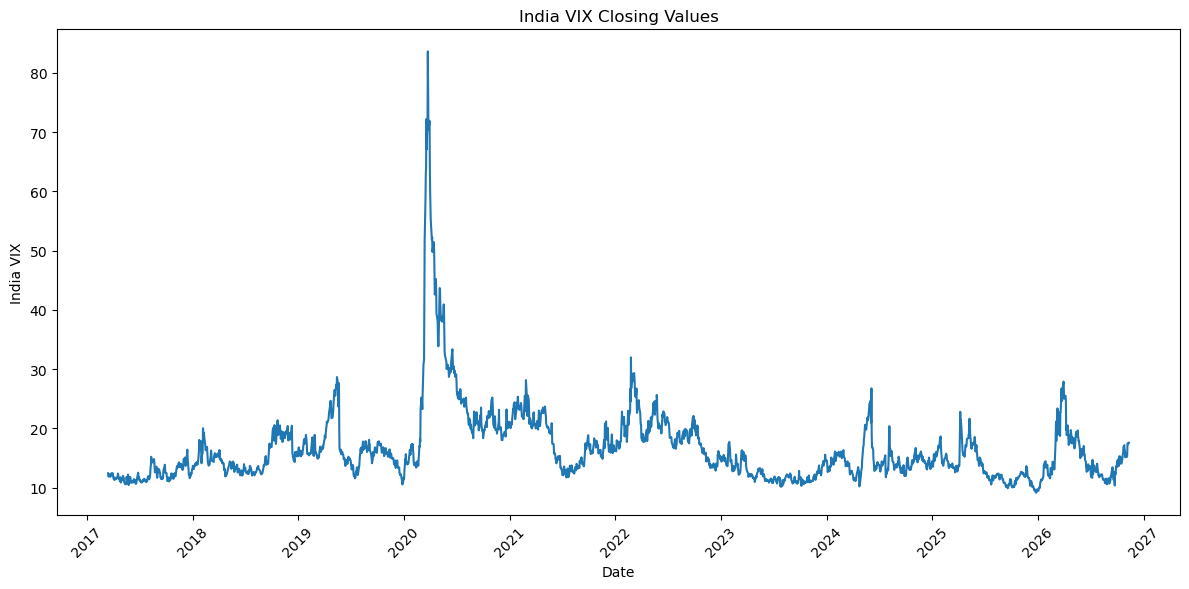

In [43]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["date"],
    df["close"]
)

plt.title(
    "India VIX Closing Values"
)

plt.xlabel("Date")
plt.ylabel("India VIX")

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

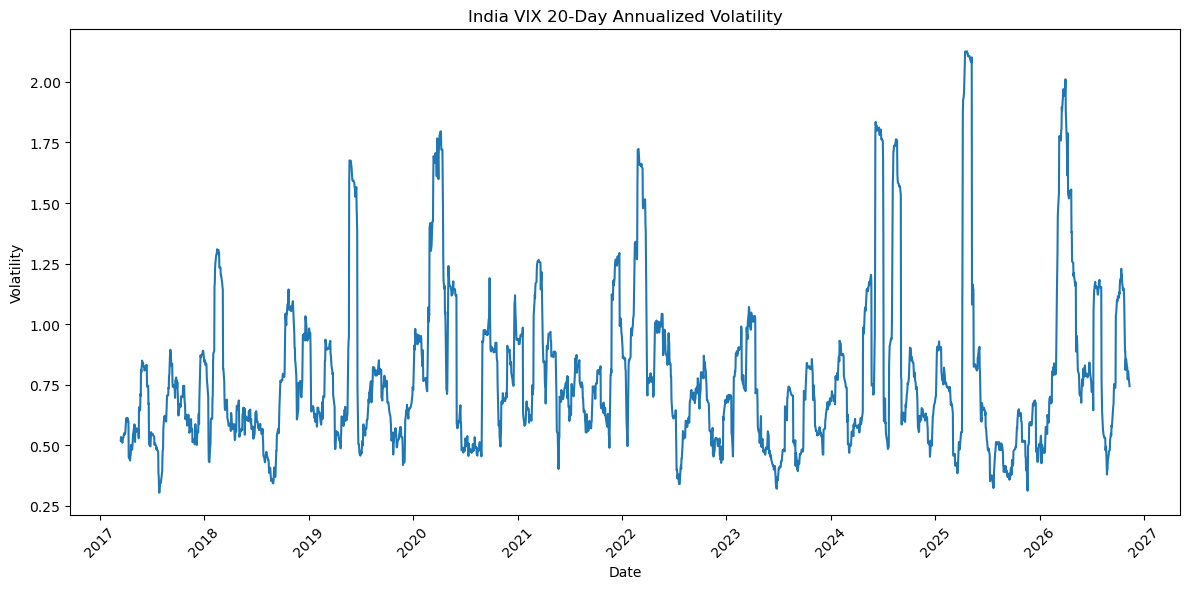

In [44]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["date"],
    df["volatility_20d"]
)

plt.title(
    "India VIX 20-Day Annualized Volatility"
)

plt.xlabel("Date")
plt.ylabel("Volatility")

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [45]:
OUTPUT_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print(
    "Processed India VIX dataset saved successfully!"
)

print(
    "Location:",
    OUTPUT_FILE
)

print(
    "Rows:",
    len(df)
)

print(
    "Columns:",
    len(df.columns)
)

Processed India VIX dataset saved successfully!
Location: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\india_vix_processed.csv
Rows: 2367
Columns: 24


In [46]:
print("Input file:", INPUT_FILE.resolve())
print("Output file:", OUTPUT_FILE.resolve())
print("DataFrame columns:", df.columns.tolist())
print("Rows:", len(df))
print("Latest date:", df["date"].max())

Input file: C:\Users\madhu\OneDrive\Documents\FINAURA\data\raw\india_vix_raw.csv
Output file: C:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\india_vix_processed.csv
DataFrame columns: ['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'volatility_5d', 'volatility_10d', 'volatility_20d', 'momentum_5d', 'momentum_20d', 'drawdown', 'vix_change', 'vix_change_pct', 'target_5d_volatility']
Rows: 2367
Latest date: 2026-11-11 00:00:00


In [47]:
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(OUTPUT_FILE, index=False)

print("VIX dataset saved successfully!")
print("Rows:", len(df))
print("Latest date:", df["date"].max())

VIX dataset saved successfully!
Rows: 2367
Latest date: 2026-11-11 00:00:00
